# K-means: From Customers to Centroids

A guided, self-checking lab, not an answer-free assessment. All records are synthetic. Read the PDF first; answer each **Before running** prompt before opening the next output. No target labels are used to fit, choose k, or report 'accuracy'.

In [1]:
from pathlib import Path
import sys
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
folder = Path.cwd()
if not (folder / 'kmeans_lab.py').exists():
    folder = folder / 'Project_03_Clustering' / 'k-means'
if not (folder / 'kmeans_lab.py').exists():
    raise FileNotFoundError('Start from the repository root or the k-means folder.')
sys.path.insert(0, str(folder))
from kmeans_lab import (TOY, TOY_IDS, INITIAL_CENTERS, lloyd_trace, squared_distances,
                        run_experiment, write_outputs, make_customers, new_model)
from sklearn.preprocessing import StandardScaler
print('Python', platform.python_version(), 'NumPy', np.__version__,
      'sklearn', sklearn.__version__, 'Matplotlib', matplotlib.__version__)
print('Features: monthly orders and average items/order. No target column.')
for name, row in zip(TOY_IDS, TOY):
    print(name, row)


Python 3.14.3 NumPy 2.5.2 sklearn 1.9.1 Matplotlib 3.11.2
Features: monthly orders and average items/order. No target column.
A [1. 1.]
B [1. 3.]
C [3. 2.]
D [7. 8.]
E [9. 7.]
F [9. 9.]


## 1. Assign before updating

A **feature** is an input column. We have two: monthly orders and average items per order. **k=2 means two centers**, each a point described by a pair of numbers. At the start, center 0 is (1,1) and center 1 is (1,3): two points, four stored numbers in total, NOT four centers.

**Before running:** Initial centers are A=(1,1) and B=(1,3). Calculate D's squared distances. C ties: use the smaller center index. Which records belong together? k counts centers, not neighbors.

In [2]:
trace = lloyd_trace(TOY, INITIAL_CENTERS)
first = trace[0]
for name, distances, label in zip(TOY_IDS, first['distances'], first['labels']):
    print(name, 'squared distances:', distances, 'cluster:', label)
print('Means after update:', first['centers_after'])
print('SSE before and after:', first['inertia_before'], first['inertia_after'])
assert np.array_equal(first['labels'], [0,1,0,1,1,1])


A squared distances: [0. 4.] cluster: 0
B squared distances: [4. 0.] cluster: 1
C squared distances: [5. 5.] cluster: 0
D squared distances: [85. 61.] cluster: 1
E squared distances: [100.  80.] cluster: 1
F squared distances: [128. 100.] cluster: 1
Means after update: [[2.   1.5 ]
 [6.5  6.75]]
SSE before and after: 246.0 66.25


## 2. Follow every iteration

**Before running:** Is one update enough? Why might B change groups? Predict the final centers, not just their cluster IDs. Each mean minimizes squared error for its fixed assigned records.

In [3]:
for step in trace:
    print('Iteration', step['iteration'], 'assignments', step['labels'])
    print('New centers:', step['centers_after'])
    print('J after assignment/update:', step['inertia_before'], step['inertia_after'],
          'shift:', step['shift'], 'converged:', step['stopped'])
assert trace[-1]['stopped']
assert np.isclose(trace[-1]['inertia_after'], 28/3)
assert all(s['inertia_after'] <= s['inertia_before'] + 1e-9 for s in trace)


Iteration 1 assignments [0 1 0 1 1 1]
New centers: [[2.   1.5 ]
 [6.5  6.75]]
J after assignment/update: 246.0 66.25 shift: 6.75 converged: False
Iteration 2 assignments [0 0 0 1 1 1]
New centers: [[1.66666667 2.        ]
 [8.33333333 8.        ]]
J after assignment/update: 25.1875 9.333333333333334 shift: 2.2988523706889543 converged: False
Iteration 3 assignments [0 0 0 1 1 1]
New centers: [[1.66666667 2.        ]
 [8.33333333 8.        ]]
J after assignment/update: 9.333333333333334 9.333333333333334 shift: 0.0 converged: True


## 3. Your turn before the check

Use P=(2,1), Q=(2,3), R=(8,7), S=(8,9), initial P and R, k=2. Calculate both distance columns, update means, show J, and check a second iteration. Then assign T=(3,2) **without moving centers**. The next cell reveals the answer.

In [4]:
practice = np.array([[2.,1.],[2.,3.],[8.,7.],[8.,9.]])
practice_trace = lloyd_trace(practice, practice[[0,2]])
for step in practice_trace:
    print(step['distances'], '\nupdated centers:', step['centers_after'],
          'J:', step['inertia_after'])
centers = practice_trace[-1]['centers_after']
distances = squared_distances(np.array([[3.,2.]]), centers)
print('T distances / assigned group:', distances, distances.argmin(axis=1))
assert np.allclose(centers, [[2,2],[8,8]])
assert np.isclose(practice_trace[-1]['inertia_after'], 4)


[[  0.  72.]
 [  4.  52.]
 [ 72.   0.]
 [100.   4.]] 
updated centers: [[2. 2.]
 [8. 8.]] J: 4.0
[[ 1. 85.]
 [ 1. 61.]
 [61.  1.]
 [85.  1.]] 
updated centers: [[2. 2.]
 [8. 8.]] J: 4.0
T distances / assigned group: [[ 1. 61.]] [0]


## 4. Calculate scaling statistics, not just substitute them

Separate invented dollar example: (2,20),(2,40),(6,20),(6,40). **Before running:** Compute mean, each squared deviation, population variance (divide by 4), and standard deviation. Scale query (6,40). Scaling learns a ruler, not the customer groups.

In [5]:
raw = np.array([[2.,20.],[2.,40.],[6.,20.],[6.,40.]])
mean = raw.sum(axis=0) / len(raw)
squared_deviations = (raw - mean)**2
sd = np.sqrt(squared_deviations.sum(axis=0) / len(raw))
print('Means:', mean, '\nSquared deviations:', squared_deviations, '\nSD:', sd)
scaler = StandardScaler().fit(raw)
assert np.allclose(mean, scaler.mean_) and np.allclose(sd, scaler.scale_)
print('Scaled rows:', scaler.transform(raw))
print('Query:', scaler.transform([[6.,40.]]))


Means: [ 4. 30.] 
Squared deviations: [[  4. 100.]
 [  4. 100.]
 [  4. 100.]
 [  4. 100.]] 
SD: [ 2. 10.]
Scaled rows: [[-1. -1.]
 [-1.  1.]
 [ 1. -1.]
 [ 1.  1.]]
Query: [[1. 1.]]


## 5. Unlabeled experiment and selecting k

600 synthetic retail records: order frequency and average basket dollars. The generator returns no target. Split 360/120/120 for training, validation, test. Training-only scaling; candidates 2-6; highest validation silhouette, smaller k on exact score ties. Freeze choices before a fresh 480-row development refit and one test evaluation. Inspect the script to trace these boundaries. This demonstration runs the predeclared whole workflow, not interactive test tuning.

In [6]:
result = run_experiment()
print('Split counts:', *(len(result[key]) for key in ['train','validation','test']))
for row in result['selection']:
    print(row)
print('Chosen k:', result['k'])
print('Pairwise ARI across 5 independent single fits:', result['stability'])
assert not set(result['development']) & set(result['test'])
assert np.allclose(result['scaler'].mean_, result['x'][result['train']].mean(axis=0))
write_outputs(result, folder / 'reports')


Split counts: 360 120 120
{'k': 2, 'train_mean_squared_distance': 0.9943903096571302, 'validation_mean_squared_distance': 0.8797388336598628, 'validation_silhouette': 0.6178368934291927, 'n_iter': 3}
{'k': 3, 'train_mean_squared_distance': 0.1473482200762761, 'validation_mean_squared_distance': 0.14780509003357842, 'validation_silhouette': 0.7968646887013282, 'n_iter': 3}
{'k': 4, 'train_mean_squared_distance': 0.11558549035579689, 'validation_mean_squared_distance': 0.11622256538607384, 'validation_silhouette': 0.7011443841473318, 'n_iter': 7}
{'k': 5, 'train_mean_squared_distance': 0.09450648356545703, 'validation_mean_squared_distance': 0.09564812509670316, 'validation_silhouette': 0.5482475948195821, 'n_iter': 5}
{'k': 6, 'train_mean_squared_distance': 0.08351726081671682, 'validation_mean_squared_distance': 0.08873859852363036, 'validation_silhouette': 0.5123273947685879, 'n_iter': 13}
Chosen k: 3
Pairwise ARI across 5 independent single fits: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Selected k: 3; five-seed pairwise ARI mean: 1.000000
Final full K-means iterations: 3
{'model': 'full_kmeans', 'mean_squared_distance': 0.129187644030178, 'silhouette': 0.7987615505371999}
{'model': 'streamed_minibatch', 'mean_squared_distance': 0.12918764403017793, 'silhouette': 0.7987615505371999}
Wrote 4 CSV files and 4 PNG figures to C:\UOP\Fall 2026\machine-learning-pathway\Project_03_Clustering\k-means\reports


## 6. Read pictures and denominators

**Before viewing:** Why does smaller training inertia not automatically choose k? Silhouette compares average within-group distance a with nearest other-group average b. It is not a percent correct. ARI here compares repeated partitions, not customer truth. Dollar-space scatterplots display assignments learned in scaled space.

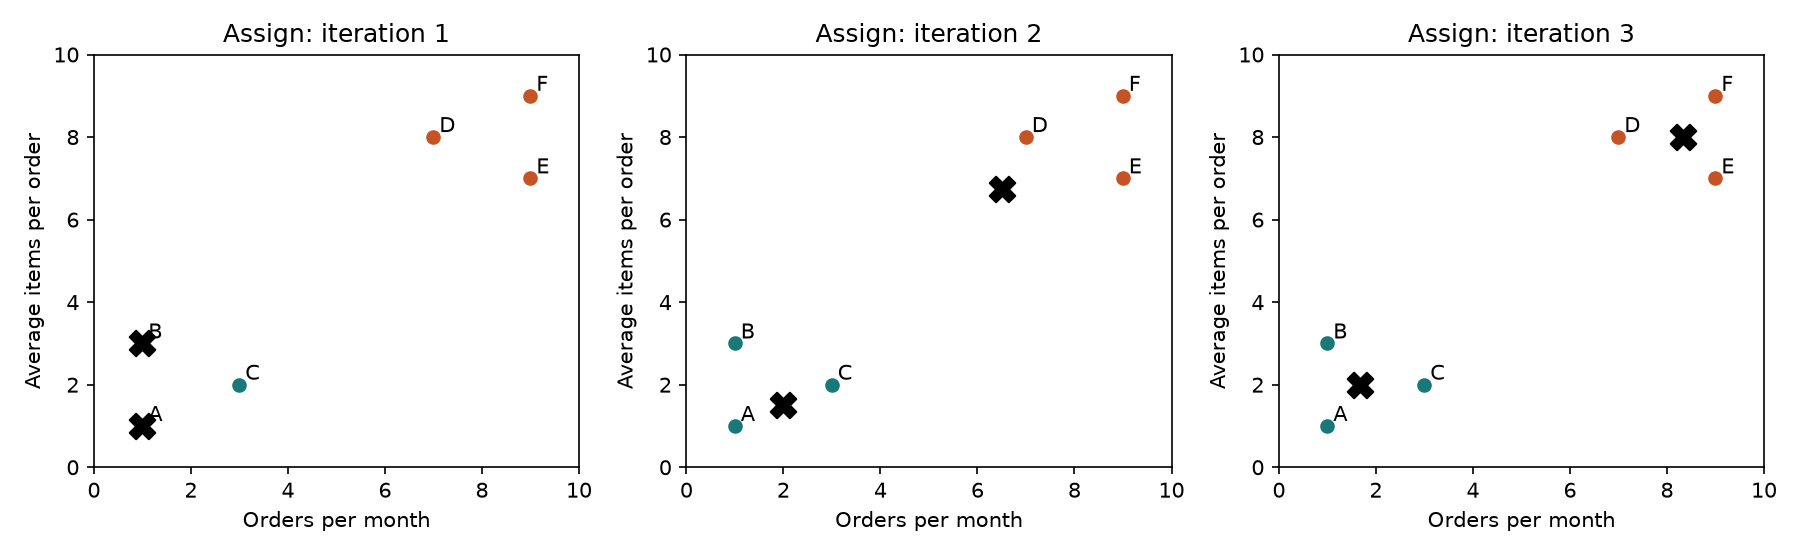

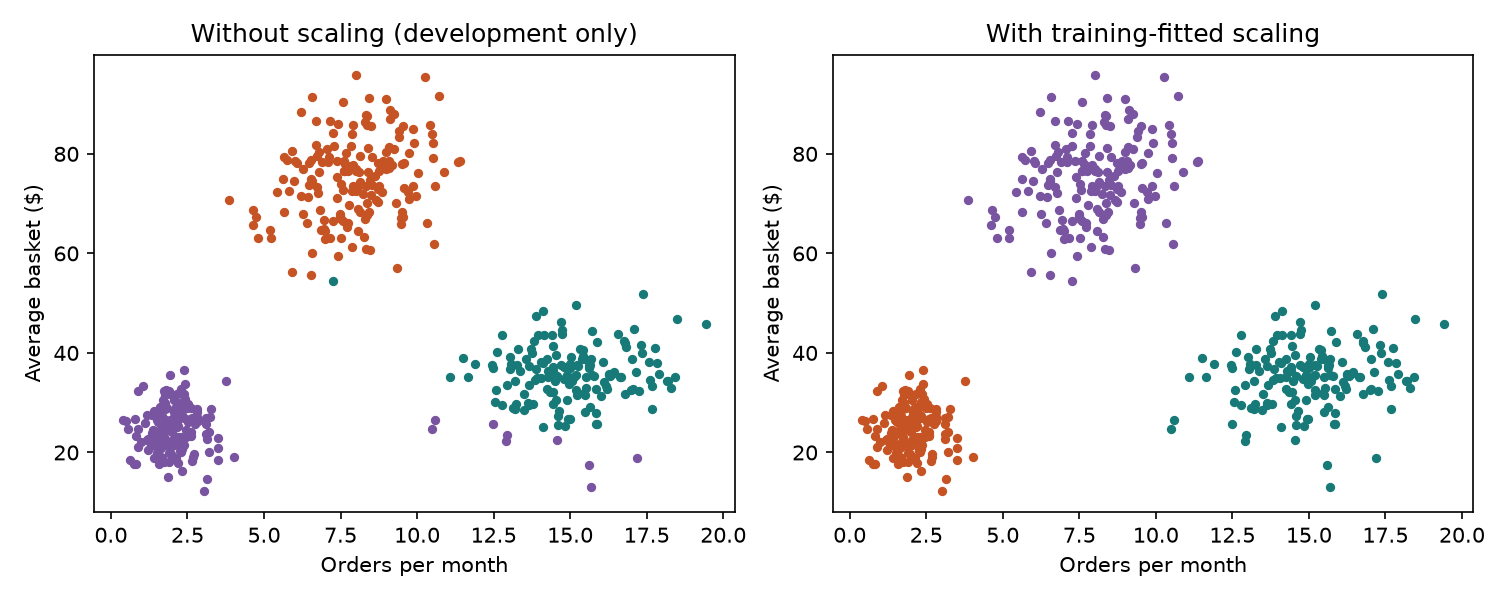

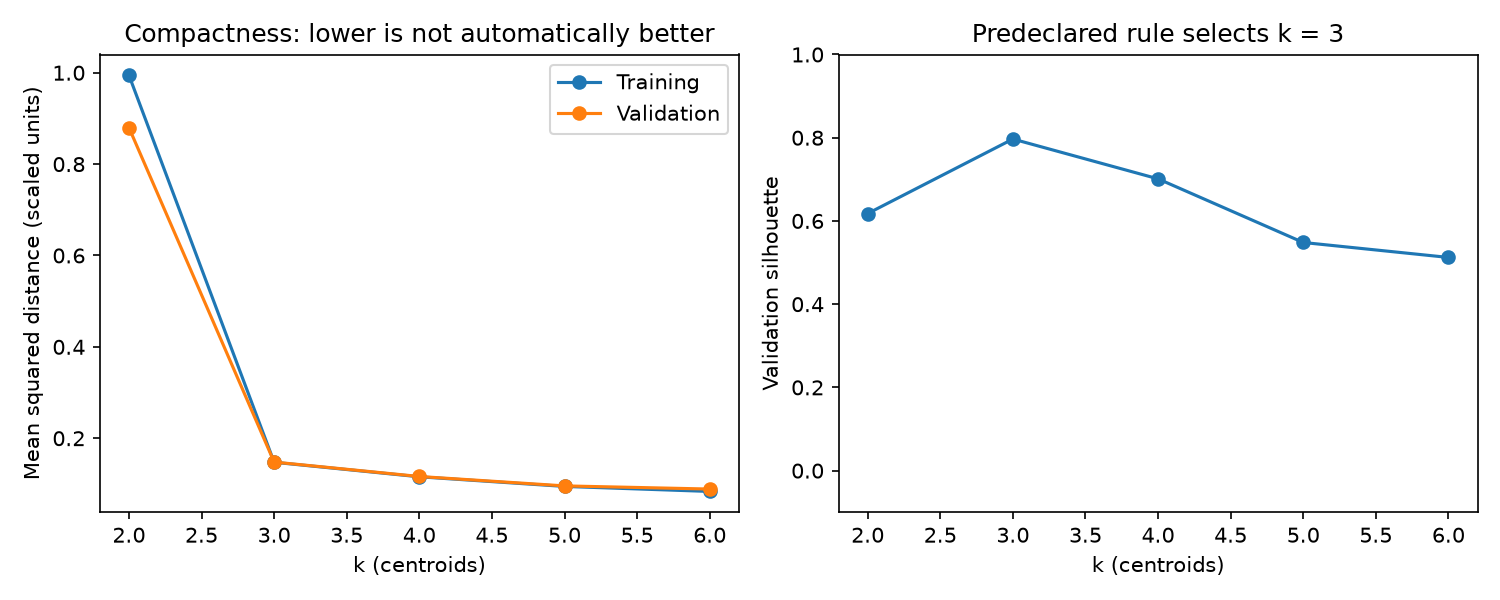

In [7]:
from IPython.display import display, Image
for filename in ['toy_iterations.png', 'scaling_comparison.png', 'k_selection.png']:
    display(Image(filename=str(folder / 'reports' / filename)))


## 7. Refit, profile, and assign a new customer

Read centers in original units using inverse_transform. Name patterns cautiously and inspect size/spread. Cluster IDs may swap between fits. **Before running:** Does predict change centers? Does its returned ID tell us a customer's real identity or a probability?

Original-unit centers: [[14.9889017  35.19885242]
 [ 2.01989429 24.83304907]
 [ 7.94682476 74.92272762]]
Development cluster sizes: [157 152 171]
New customer (5 orders/month, $50 basket) assigned to: [2]
Retained full-model iterations: 3
Test results, not accuracy: [{'model': 'full_kmeans', 'mean_squared_distance': 0.129187644030178, 'silhouette': 0.7987615505371999}, {'model': 'streamed_minibatch', 'mean_squared_distance': 0.12918764403017793, 'silhouette': 0.7987615505371999}]


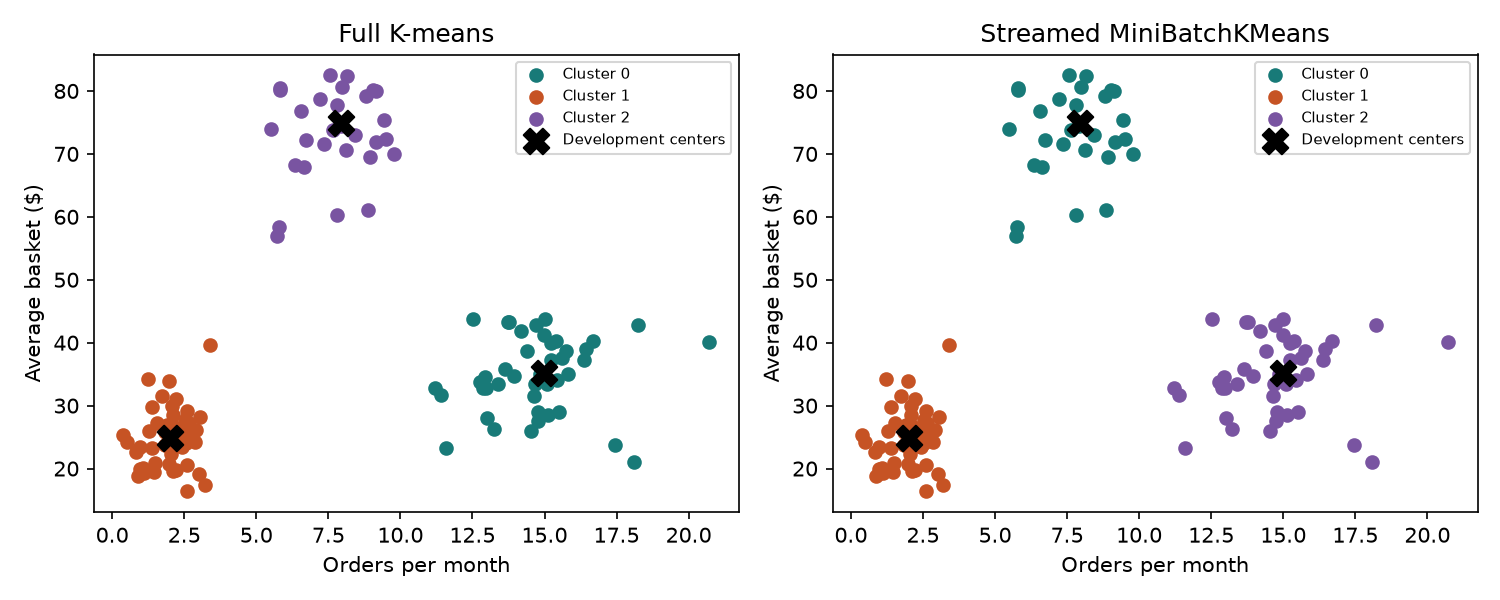

In [8]:
model = result['final']
scaler = result['final_scaler']
print('Original-unit centers:', scaler.inverse_transform(model.cluster_centers_))
print('Development cluster sizes:', np.bincount(model.labels_))
new_customer = np.array([[5.,50.]])
saved = model.cluster_centers_.copy()
group = model.predict(scaler.transform(new_customer))
print('New customer (5 orders/month, $50 basket) assigned to:', group)
assert np.array_equal(saved, model.cluster_centers_)
print('Retained full-model iterations:', model.n_iter_)
print('Test results, not accuracy:', result['test_results'])
display(Image(filename=str(folder / 'reports' / 'test_clusters.png')))


## 8. Mini-batches update centers; KNN query batches do not

Inspect stream_minibatches: caller supplies shuffled batches and five passes. Its StandardScaler is fixed on development before streaming. This is a work budget, not a convergence claim. partial_fit does not automatically implement a global max_iter or max_no_improvement loop. Full Lloyd instead holds centers fixed through a whole pass before averaging. Mini-batch full-data inertia need not fall after every update. Equal results on this easy case do not establish equal behavior everywhere.

In [9]:
for row in result['test_results']:
    print(row)
assert not hasattr(result['final'], 'partial_fit')
assert hasattr(result['mini'], 'partial_fit')
n, k, d = 85_000_000, 3, 2
print('Hypothetical raw bytes:', n*d*8)
print('Point-center comparisons/pass:', n*k)
print('20 passes, 10 full KMeans starts:', n*k*20*10)
print('100,000-row chunks/pass:', n//100_000)


{'model': 'full_kmeans', 'mean_squared_distance': 0.129187644030178, 'silhouette': 0.7987615505371999}
{'model': 'streamed_minibatch', 'mean_squared_distance': 0.12918764403017793, 'silhouette': 0.7987615505371999}
Hypothetical raw bytes: 1360000000
Point-center comparisons/pass: 255000000
20 passes, 10 full KMeans starts: 51000000000
100,000-row chunks/pass: 850


## Reflect and extend without leaking test data

1. Explain why convergence does not choose k or prove useful segments.
2. Which feature might dominate without scaling, and what does scaling assume?
3. Calculate silhouette for a=.4, b=1; explain its denominator.
4. Why does sampled silhouette avoid an infeasible 85M-squared calculation?
5. Explain n_init for full KMeans versus MiniBatchKMeans.
6. Sketch a global-scaler, two-pass streaming workflow with a development monitor.
7. Why are equal-density blobs an easy case? What if groups curve or overlap?
8. Try a new seed, skewed/noisy generator, or k range only with a fresh development/evaluation plan; do not retune on this already-opened test set.

Complete the separate homework and student rubric for independent evidence. Sources: scikit-learn KMeans, MiniBatchKMeans, silhouette_score and adjusted_rand_score documentation (linked in README).